# Figure 1 | Snow modeling sites near Juneau, Alaska

Panel A shows the three manuscript sites on Esri World Imagery. Panel B adds
the native HRRR-AK temperature grid for the comparison timestamp used in
`figure1_basemap.ipynb`. Both panels use the same UTM zone 8N extent and the
[U.S. Census Bureau TIGER/Line coastline](https://www.census.gov/geographies/mapping-files/time-series/geo/tiger-line-file.html). Panel B retains
the oversized Alaska locator inset.

Run with the manuscript's rasterio environment. Figure files are written to
`figures/files/` as PNG (300 dpi) and PDF. Imagery and shoreline downloads are
cached under `BASEMAP_CACHE` (default `/tmp/juneau_figure1_basemaps`).

In [7]:
from pathlib import Path
import hashlib
import io
import json
import os
import shutil
import tempfile
from urllib.parse import urlencode
from urllib.request import Request, urlopen
from zipfile import ZipFile

import cartopy.crs as ccrs
import geopandas as gpd
import matplotlib.patheffects as pe
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.ticker import FixedLocator
from matplotlib.colors import TwoSlopeNorm
from matplotlib_scalebar.scalebar import ScaleBar
import numpy as np
from PIL import Image
from pyproj import CRS, Transformer
import pygrib
from shapely.geometry import box
import xarray as xr

REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
                 if (p / 'envs/rasterio.yml').is_file() and (p / 'figures').is_dir())
OUTPUT_DIR = REPO_ROOT / 'figures/files'
archive = Path('/hdd/snow_hydrology/hrrrak')
extent_source = archive / 'large_juneau_domain/netcdf/hrrrak_merged_grib_f567_WY2025_utm.nc'
GRIB = Path(os.environ.get(
    'JUNEAU_FIGURE1_GRIB',
    archive / 'icefield_domain/f567/WY2025/hrrr.20250220/hrrr.t12z.wrfsfcf06.ak.grib2',
))
alaska_shp = Path('/hdd/snow_hydrology/shape_files/alaska_censusdotgov.shp')

# Preserve the original plotting extent. Read the forecast from the native archive.
with xr.open_dataset(extent_source) as ds:
    xmin, xmax = float(ds.x.min()), float(ds.x.max())
    ymin, ymax = float(ds.y.min()), float(ds.y.max())

proj = ccrs.UTM(8)
pc = ccrs.PlateCarree()
UTM = 32608
to_utm = Transformer.from_crs(4326, UTM, always_xy=True)
plt.rcParams.update({'font.family': 'DejaVu Sans', 'pdf.fonttype': 42})

## Satellite imagery and shoreline

The imagery and 2025 TIGER/Line coastline are plotted in the same CRS. The
coastline is clipped to the map extent and covers the northern channels and
islands as well as the Juneau waterfront. The first run without a cache
downloads the TIGER/Line coastline archive (about 17 MB).

In [2]:
BASEMAP_CACHE = Path(os.environ.get('BASEMAP_CACHE',
    str(Path(tempfile.gettempdir()) / 'juneau_figure1_basemaps')))
BASEMAP_CACHE.mkdir(parents=True, exist_ok=True)
BASEMAP_SERVICE = 'https://services.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer'
service = BASEMAP_SERVICE
# Preserve the map aspect ratio in the image request.
image_width = 1400
image_height = min(1800, round(image_width * (ymax-ymin) / (xmax-xmin)))
params = dict(bbox=f'{xmin},{ymin},{xmax},{ymax}', bboxSR=32608, imageSR=32608,
              size=f'{image_width},{image_height}', format='png', transparent='false', f='json')
cache_settings = params
key = hashlib.sha256(json.dumps(cache_settings, sort_keys=True).encode()).hexdigest()[:16]
image_file = BASEMAP_CACHE / f'esri_{key}.png'
metadata_file = BASEMAP_CACHE / f'esri_{key}.json'
def fetch(url):
    req = Request(url, headers={'User-Agent': 'JuneauSnowModelingResearch/1.0'})
    import time
    from urllib.error import HTTPError, URLError
    for attempt in range(3):
        try:
            with urlopen(req, timeout=60) as response:
                return response.read()
        except (HTTPError, URLError, TimeoutError):
            if attempt == 2:
                raise
            time.sleep(2)
if not image_file.exists() or not metadata_file.exists():
    image_info = json.loads(fetch(service + '/export?' + urlencode(params)))
    if 'error' in image_info:
        raise RuntimeError(image_info['error'])
    image_bytes = fetch(image_info['href'])
    Image.open(io.BytesIO(image_bytes)).verify()
    image_file.write_bytes(image_bytes)
    metadata_file.write_text(json.dumps(image_info, indent=2))
image_info = json.loads(metadata_file.read_text())
b = image_info['extent']
basemap_extent = [b['xmin'], b['xmax'], b['ymin'], b['ymax']]
basemap_rgb = np.asarray(Image.open(image_file).convert('RGB'))
print('Basemap:', basemap_rgb.shape, 'extent:', basemap_extent)
ATTRIBUTION = 'Imagery: Esri, Vantor, Earthstar Geographics, and the GIS User Community'

Basemap: (1768, 1400, 3) extent: [497947.25484336715, 554423.3224103136, 6447484.592103873, 6518805.797431274]


In [9]:
shore_url = 'https://www2.census.gov/geo/tiger/TIGER2025/COASTLINE/tl_2025_us_coastline.zip'
shore_archive = BASEMAP_CACHE / 'tl_2025_us_coastline.zip'
if not shore_archive.is_file():
    pending = shore_archive.with_suffix('.part')
    with urlopen(shore_url, timeout=90) as response, pending.open('wb') as output:
        shutil.copyfileobj(response, output)
    with ZipFile(pending) as archive_zip:
        shoreline_members = [name for name in archive_zip.namelist() if name.endswith('.shp')]
        if len(shoreline_members) != 1:
            raise ValueError('Expected one shapefile in the TIGER/Line coastline archive.')
    pending.replace(shore_archive)

with ZipFile(shore_archive) as archive_zip:
    shoreline_member, = [name for name in archive_zip.namelist() if name.endswith('.shp')]
utm_bounds = (xmin, ymin, xmax, ymax)
wgs84_bounds = Transformer.from_crs(UTM, 4326, always_xy=True).transform_bounds(*utm_bounds)
shoreline = gpd.read_file(f'zip://{shore_archive}!{shoreline_member}', bbox=wgs84_bounds)
shoreline = shoreline.to_crs(UTM).clip(box(*utm_bounds))
if shoreline.empty:
    raise ValueError('The TIGER/Line coastline selection is empty.')
alaska = gpd.read_file(alaska_shp)

## Native HRRR-AK grid

The 2 m air temperature is valid at 18:00 UTC on 20 February 2025. Cell
edges are half a grid spacing from their centers in the GRIB projection,
then transformed to UTM. The color scale retains the original ±5 °C limits.

In [10]:
if not GRIB.is_file():
    raise FileNotFoundError(f'{GRIB} is missing. Set JIF_GRIB to a local HRRR-AK GRIB2 file.')

with pygrib.open(str(GRIB)) as fields:
    temperature_field, = fields.select(shortName='2t', typeOfLevel='heightAboveGround', level=2)
    temperature = temperature_field.values - 273.15
    lat, lon = temperature_field.latlons()
    native = CRS.from_dict(temperature_field.projparams)
    dx, dy = temperature_field['DxInMetres'], temperature_field['DyInMetres']
    initialized, valid = temperature_field.analDate, temperature_field.validDate

to_native = Transformer.from_crs(4326, native, always_xy=True)
native_to_utm = Transformer.from_crs(native, UTM, always_xy=True)
center_x, center_y = to_native.transform(lon, lat)
ny, nx = temperature.shape
x = center_x[0, 0] + np.arange(nx) * np.copysign(dx, center_x[0, -1] - center_x[0, 0])
y = center_y[0, 0] + np.arange(ny) * np.copysign(dy, center_y[-1, 0] - center_y[0, 0])
if not (np.allclose(center_x, x[None, :], atol=2, rtol=0)
        and np.allclose(center_y, y[:, None], atol=2, rtol=0)):
    raise ValueError('Decoded coordinates do not match a regular native HRRR-AK grid.')

x_edges = x[0] + (np.arange(nx + 1) - 0.5) * np.copysign(dx, x[-1] - x[0])
y_edges = y[0] + (np.arange(ny + 1) - 0.5) * np.copysign(dy, y[-1] - y[0])
grid_x, grid_y = native_to_utm.transform(*np.meshgrid(x_edges, y_edges))

## Map layout

Mendenhall Glacier and the Juneau Icefield provide regional context. The glacier
label is placed near the [Census Bureau glacier inventory](https://tigerweb.geo.census.gov/tigerwebmain/Files/acs24/tigerweb_acs24_glaciers_us.html)
reference point. The original site locations, elevations, and inset geometry
are retained.

In [11]:
sites = {
    'PPSA': (-134.51700, 58.26200, 670, 7, -7),
    'TRAM': (-134.38600, 58.29710, 529, 7, 6),
    'HEEN': (-134.86448, 58.69652, 640, 7, 6),
}
text_halo = [pe.withStroke(linewidth=2.1, foreground='#18242d')]

def map_label(ax, label, lon, lat, *, offset=(0, 0), fontsize=8, **style):
    ax.annotate(label, to_utm.transform(lon, lat), xytext=offset,
                textcoords='offset points', ha='left', va='center', multialignment='left',
                fontsize=fontsize, color='white', path_effects=text_halo, zorder=12, **style)

def draw_panel(ax, *, overlay=False, left_labels=True, dem=None):
    ax.set_extent([xmin, xmax, ymin, ymax], crs=proj)
    ax.imshow(basemap_rgb, extent=basemap_extent, origin='upper',
              transform=proj, interpolation='antialiased', zorder=1)

    mesh = None
    if overlay:
        mesh = ax.pcolormesh(grid_x, grid_y, temperature, shading='flat', cmap='coolwarm',
                             norm=TwoSlopeNorm(vmin=-5, vcenter=0, vmax=5),
                             alpha=0.40, zorder=2)
        grid = np.stack((grid_x, grid_y), axis=-1)
        lines = [*grid, *grid.transpose(1, 0, 2)]
        ax.add_collection(LineCollection(lines, colors=[(0.08, 0.12, 0.17, 0.65)],
                                         linewidths=0.48, zorder=3))

    if dem is not None:
        contours = ax.contour(*dem, levels=[250, 500, 750, 1000, 1250, 1500],
                              colors='#25333d', linewidths=0.32, alpha=0.58, zorder=4)
        ax.clabel(contours, levels=[500, 1000, 1500], fmt='%d m', fontsize=6)

    ax.add_geometries(shoreline.geometry, crs=proj, facecolor='none',
                      edgecolor='#d8edf2', linewidth=0.42, alpha=0.85, zorder=5)
    gl = ax.gridlines(draw_labels=True, linewidth=0.30, color='#d7e4e7',
                      alpha=0.38, linestyle=':', zorder=6)
    gl.top_labels = gl.right_labels = False
    gl.left_labels = left_labels
    gl.xlabel_style = gl.ylabel_style = {'size': 8}
    gl.xlocator = FixedLocator([-134.95, -134.8, -134.65, -134.5, -134.35, -134.2])

    for site, (lon, lat, elev, dx, dy) in sites.items():
        ax.scatter(*to_utm.transform(lon, lat), s=36, marker='o',
                   color='#f39547', edgecolor='#17232c', linewidth=0.9, zorder=11)
        map_label(ax, f'{site}\n{elev} m', lon, lat, offset=(dx, dy),
                  fontsize=8.5, fontweight='bold')

    airport = (-134.576, 58.354)
    ax.scatter(*to_utm.transform(*airport), s=21, marker='s',
               color='#17232c', edgecolor='white', linewidth=0.65, zorder=10)
    map_label(ax, 'JNU Airport', *airport, offset=(-20, 10))
    map_label(ax, 'Douglas Island', -134.69, 58.30, fontstyle='italic')
    map_label(ax, 'Mendenhall Glacier', -134.53, 58.505, fontstyle='italic',
              offset=(6, 5))
    if not overlay:
        map_label(ax, 'Juneau Icefield', -134.46, 58.72, fontstyle='italic', fontsize=9)

    ax.add_artist(ScaleBar(dx=1, units='m', location='lower left', fixed_value=10,
                           fixed_units='km', box_alpha=0.62, font_properties={'size': 8}))
    arrow = ax.annotate('N', xy=(0.045, 0.17), xytext=(0.045, 0.08),
                        xycoords='axes fraction', ha='center', va='center',
                        fontsize=8, color='white', zorder=20,
                        arrowprops=dict(arrowstyle='-|>', color='white', lw=1.15))
    arrow.set_path_effects(text_halo)
    arrow.arrow_patch.set_path_effects(text_halo)
    ax.spines['geo'].set_visible(False)
    return mesh

def alaska_inset(ax):
    return ax.inset_axes([0.43, 0.62, 0.80, 0.47],
        projection=ccrs.AlbersEqualArea(central_longitude=-154,
            central_latitude=50, standard_parallels=(55, 65)))

Saved /home/cassie/python/repos/juneau_snow_modeling_manuscript/figures/files/figure1_satellite_publication.png
Saved /home/cassie/python/repos/juneau_snow_modeling_manuscript/figures/files/figure1_satellite_publication.pdf


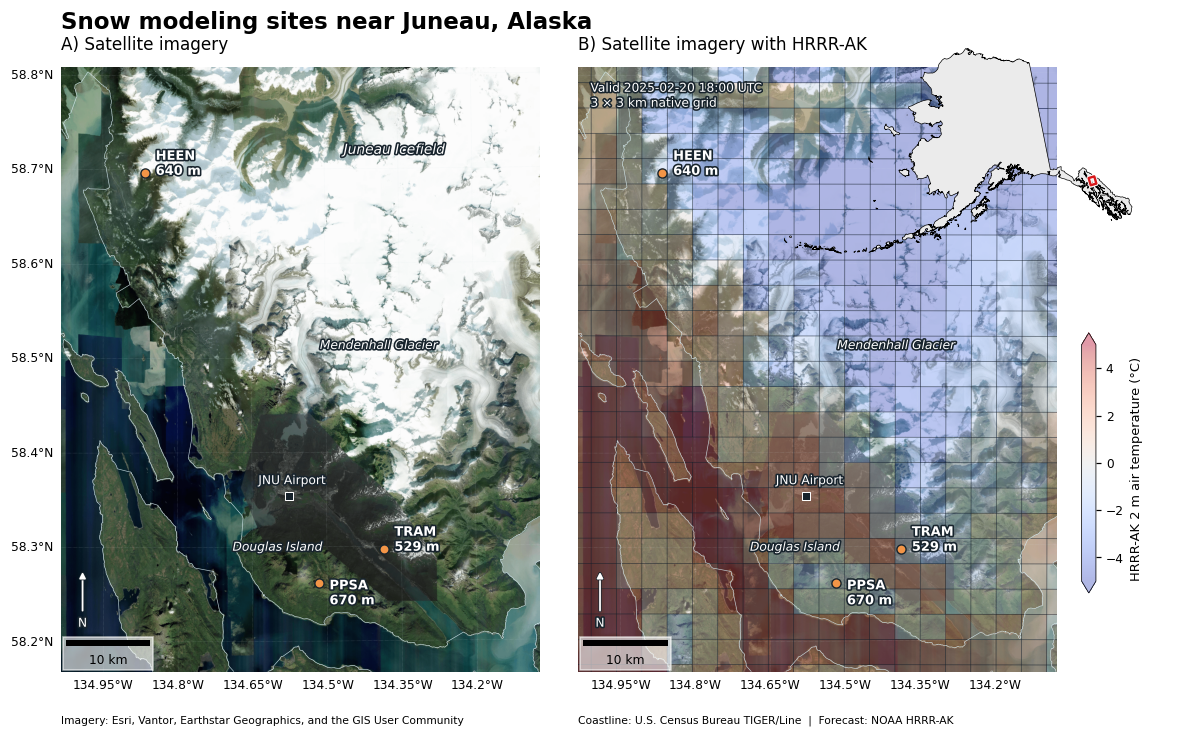

In [6]:
def publication_figure(stem, *, dem=None):
    map_height = 5.5
    map_width = map_height * (xmax - xmin) / (ymax - ymin)
    left, bottom, gap = 0.65, 0.72, 0.35
    right, top = 1.45, 0.68
    width = left + 2 * map_width + gap + right
    height = bottom + map_height + top
    second = left + map_width + gap

    fig = plt.figure(figsize=(width, height), dpi=150)
    def map_rect(x_left):
        return [x_left / width, bottom / height, map_width / width, map_height / height]

    ax_a = fig.add_axes(map_rect(left), projection=proj)
    ax_b = fig.add_axes(map_rect(second), projection=proj)
    cax = fig.add_axes([(second + map_width + 0.22) / width,
                        (bottom + 0.13 * map_height) / height,
                        0.13 / width, 0.43 * map_height / height])
    draw_panel(ax_a)
    mesh = draw_panel(ax_b, overlay=True, left_labels=False, dem=dem)
    cbar = fig.colorbar(mesh, cax=cax, extend='both')
    cbar.set_label('HRRR-AK 2 m air temperature (°C)', fontsize=8.5, loc='bottom')
    cbar.ax.tick_params(labelsize=8, length=3)
    cbar.outline.set_linewidth(0.5)

    inset = alaska_inset(ax_b)
    alaska.to_crs(inset.projection.proj4_init).plot(
        ax=inset, facecolor='0.92', edgecolor='black', linewidth=0.45, zorder=1,
    )
    inset.add_geometries([box(xmin, ymin, xmax, ymax)], crs=proj,
                         facecolor='none', edgecolor='white', linewidth=2.9, zorder=4)
    inset.add_geometries([box(xmin, ymin, xmax, ymax)], crs=proj,
                         facecolor='none', edgecolor='#d7191c', linewidth=1.6, zorder=5)
    inset.set_extent([-180, -128, 50, 73], crs=pc)
    inset.set_axis_off()

    fig.text(left / width, 0.975, 'Snow modeling sites near Juneau, Alaska',
             ha='left', va='top', fontsize=15, weight='bold')
    subtitle_y = (bottom + map_height + 0.12) / height
    fig.text(left / width, subtitle_y, 'A) Satellite imagery',
             ha='left', va='bottom', fontsize=11, weight='normal')
    subtitle_b = 'B) Satellite imagery with HRRR-AK'
    if dem is not None:
        subtitle_b = 'B) HRRR-AK and DEM contours'
    fig.text(second / width, subtitle_y, subtitle_b,
             ha='left', va='bottom', fontsize=11, weight='normal')
    ax_b.text(0.025, 0.975, f'Valid {valid:%Y-%m-%d %H:%M} UTC\n'
              f'{dx / 1000:g} × {dy / 1000:g} km native grid', transform=ax_b.transAxes,
              ha='left', va='top', multialignment='left', color='white',
              fontsize=8, path_effects=text_halo, zorder=16)
    fig.text(left / width, 0.036, ATTRIBUTION, fontsize=7, ha='left')
    fig.text(second / width, 0.036, 'Coastline: U.S. Census Bureau TIGER/Line  |  Forecast: NOAA HRRR-AK',
             fontsize=7, ha='left')
    if dem is not None:
        fig.text(second / width, 0.014, 'Elevation contours: ArcticDEM, 20 m mosaic',
                 fontsize=7, ha='left')

    fig.canvas.draw()
    np.testing.assert_allclose(ax_a.get_extent(proj), ax_b.get_extent(proj), atol=1e-5)
    np.testing.assert_allclose(ax_a.get_window_extent().size, ax_b.get_window_extent().size)
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    for extension in ('png', 'pdf'):
        path = OUTPUT_DIR / f'{stem}.{extension}'
        fig.savefig(path, dpi=300, bbox_inches='tight', pad_inches=0.08, facecolor='white')
        print(f'Saved {path}')
    return fig


fig = publication_figure('figure1_satellite_publication')
plt.show()

## Alternate version with ArcticDEM contours

Panel B adds contours from the merged 20 m ArcticDEM mosaic. Contours run
from 250 to 1,500 m at 250 m intervals, with elevations labeled every 500 m.
The alternate figure has its own PNG and PDF exports.

Contour source: jif_tiles_utm8n_20m.tif; EPSG:32608; (20.0, 20.0) m
Map window: (3569, 2727); valid pixels: 9,728,527/9,732,663
Saved /home/cassie/python/repos/juneau_snow_modeling_manuscript/figures/files/figure1_satellite_publication_dem.png
Saved /home/cassie/python/repos/juneau_snow_modeling_manuscript/figures/files/figure1_satellite_publication_dem.pdf


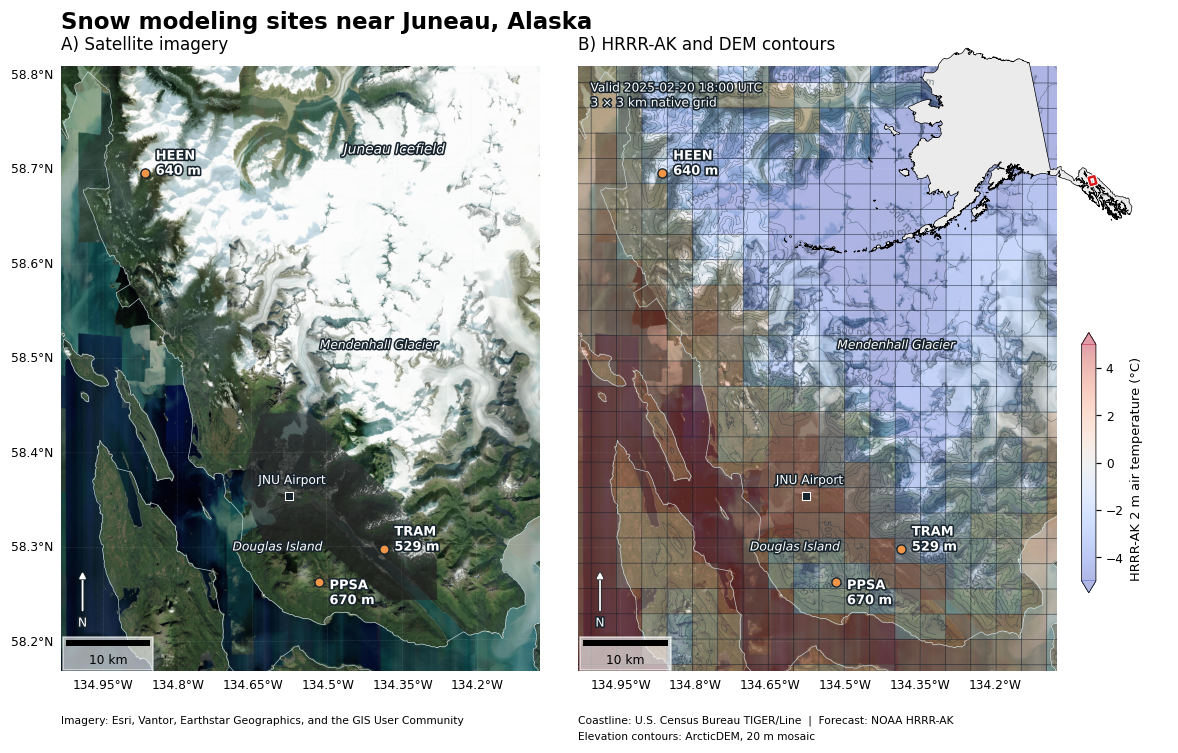

In [7]:
import rasterio
from rasterio.windows import Window, from_bounds

DEM_PATH = Path('/hdd/snow_hydrology/DEMs/ArcticDEM_edits/icefield_domain/jif_mosaic/jif_tiles_utm8n_20m.tif')

with rasterio.open(DEM_PATH) as src:
    if CRS(src.crs) != CRS.from_epsg(32608):
        raise ValueError(f'Expected WGS 84 / UTM 8N, found {src.crs}')
    if not np.allclose(src.res, (20, 20)):
        raise ValueError(f'Expected a 20 m mosaic, found {src.res}')
    # Pad by one pixel for contours crossing the fixed map boundary.
    requested = from_bounds(xmin - 20, ymin - 20, xmax + 20, ymax + 20, src.transform)
    c0, r0 = int(np.floor(requested.col_off)), int(np.floor(requested.row_off))
    c1, r1 = int(np.ceil(requested.col_off + requested.width)), int(np.ceil(requested.row_off + requested.height))
    window = Window(c0, r0, c1 - c0, r1 - r0).intersection(Window(0, 0, src.width, src.height))
    dem_z = src.read(1, window=window, masked=True).astype('float32')
    transform = src.window_transform(window)
    dem_x = transform.c + (np.arange(dem_z.shape[1]) + 0.5) * transform.a
    dem_y = transform.f + (np.arange(dem_z.shape[0]) + 0.5) * transform.e
    print(f'Contour source: {DEM_PATH.name}; {src.crs}; {src.res} m')
    print(f'Map window: {dem_z.shape}; valid pixels: {dem_z.count():,}/{dem_z.size:,}')
if dem_z.count() == 0:
    raise ValueError('No valid DEM elevations in the map window.')


fig = publication_figure('figure1_satellite_publication_dem', dem=(dem_x, dem_y, dem_z))
plt.show()